In [2]:
# ═══ 0. 设置 ═══
import os, sys
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')   # 防止 Windows 上 OpenMP 运行库重复加载导致内核崩溃
from pathlib import Path
ROOT = Path.cwd()                      # 本 notebook 所在目录 = 项目根目录
sys.path.insert(0, str(ROOT))

SMOKE = False        # True：冒烟测试（极小规模）；False：正式实验
# 并行设置：务必保证 WORKERS × THREADS ≤ 物理核数（超额订阅会让速度下降数倍）
WORKERS = 3         # 并行进程数（24 核建议 3–6；显存 / 内存不足时调小）
THREADS = 4         # 每个进程的 CPU 线程数

# 逐个导入并打印进度：若内核在这里崩溃，最后一行打印的内容就是出问题的那一步
print('1/4 导入 torch …', flush=True)
import torch
print('    torch', torch.__version__, '| CUDA:', torch.cuda.is_available(), flush=True)
print('2/4 导入 numpy / pandas / scipy …', flush=True)
import numpy as np, pandas as pd, scipy
print('3/4 导入 matplotlib …', flush=True)
import matplotlib
print('4/4 导入实验代码 cpm …', flush=True)
from cpm import config as C
from cpm.experiments import (run_experiment, run_group, run_tuning_search, run_tuning_confirm, run_upper_bound, run_exploit,
                             run_overhead, results_root, figures_root, load_tuned)
from cpm.network import run_netshock, run_recovery
from cpm import analysis as A, figures as Fg
from cpm.calibration import calibration_report
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
print('✅ 设置完成 | 模式:', '冒烟' if SMOKE else '正式')
print('结果目录:', results_root(SMOKE), '| 图目录:', figures_root(SMOKE))

1/4 导入 torch …
    torch 2.12.1+cu132 | CUDA: True
2/4 导入 numpy / pandas / scipy …
3/4 导入 matplotlib …
4/4 导入实验代码 cpm …
✅ 设置完成 | 模式: 正式
结果目录: C:\Users\Administrator\Desktop\多智能体强化学习定价\最终稿\cpm_v3\results | 图目录: C:\Users\Administrator\Desktop\多智能体强化学习定价\最终稿\cpm_v3\figures


# 算电协同补充实验（对已有结果的补充，不改变任何已有设定与结果）

替换代码文件后：**重启内核 → 运行上面的"设置"cell（只导入）→ 依次运行下面三个 cell**。

| 情景 | 电价 | 需求 | 来源 |
|---|---|---|---|
| main | 分时 | ξ = 0.1（正文数据） | 已有 |
| flat | 平坦 | ξ = 0 | 已有（sens_tariff_flat） |
| pv1.5 / pv2 | 峰谷差 × 1.5 / × 2 | ξ = 0.15 / 0.2 | 新训练 2 次 |

另做不训练的评估：用于三步分解（电价成本 → 需求调整 → 策略重新学习）的中间状态，正向（从正文出发）与反向（从平坦出发）各两个；正文策略面对峰谷差放大；正文条件下的四种规则基准（分时段对照）。

## 1. 训练两个峰谷差放大情景（main 与 sens_tariff_flat 已有，自动跳过）

In [4]:
from cpm import energy as EN
EN.run_energy_training(workers=WORKERS, smoke=SMOKE, threads=THREADS)

📋 4 个作业：['main', 'sens_tariff_flat', 'energy_pv_1.5', 'energy_pv_2']
[1/4] main / seed 0 → skip（0.0 min）| 已用 0.0 min
[2/4] energy_pv_1.5 / seed 0 → skip（0.0 min）| 已用 0.0 min
[3/4] sens_tariff_flat / seed 0 → skip（0.0 min）| 已用 0.0 min
[4/4] energy_pv_2 / seed 0 → skip（0.0 min）| 已用 0.0 min
✅ 完成


[('main', 0, 'skip', 0.0),
 ('energy_pv_1.5', 0, 'skip', 0.0),
 ('sens_tariff_flat', 0, 'skip', 0.0),
 ('energy_pv_2', 0, 'skip', 0.0)]

## 2. 评估（不训练，共 14 次；已完成的自动跳过，本次只新增 2 次反向评估）

In [5]:
EN.run_energy_eval(workers=WORKERS, smoke=SMOKE, threads=THREADS)

📋 评估作业 0 个
✅ 评估完成


[]

## 3. 核查、表与图（只读结果，可反复运行）
复现核查应全部 identical = True；表在 `results/energy/tables/`，图在 `figures/energy/`。

复现核查：8 项，0 项不一致
  🖼 energy/Fig_energy_hourly.png（绘图数据：energy/data/Fig_energy_hourly*.csv）




  🖼 energy/Fig_energy_amplitude.png（绘图数据：energy/data/Fig_energy_amplitude*.csv）




  🖼 energy/Fig_energy_decomposition.png（绘图数据：energy/data/Fig_energy_decomposition*.csv）




  🖼 energy/Fig_energy_period_methods.png（绘图数据：energy/data/Fig_energy_period_methods*.csv）


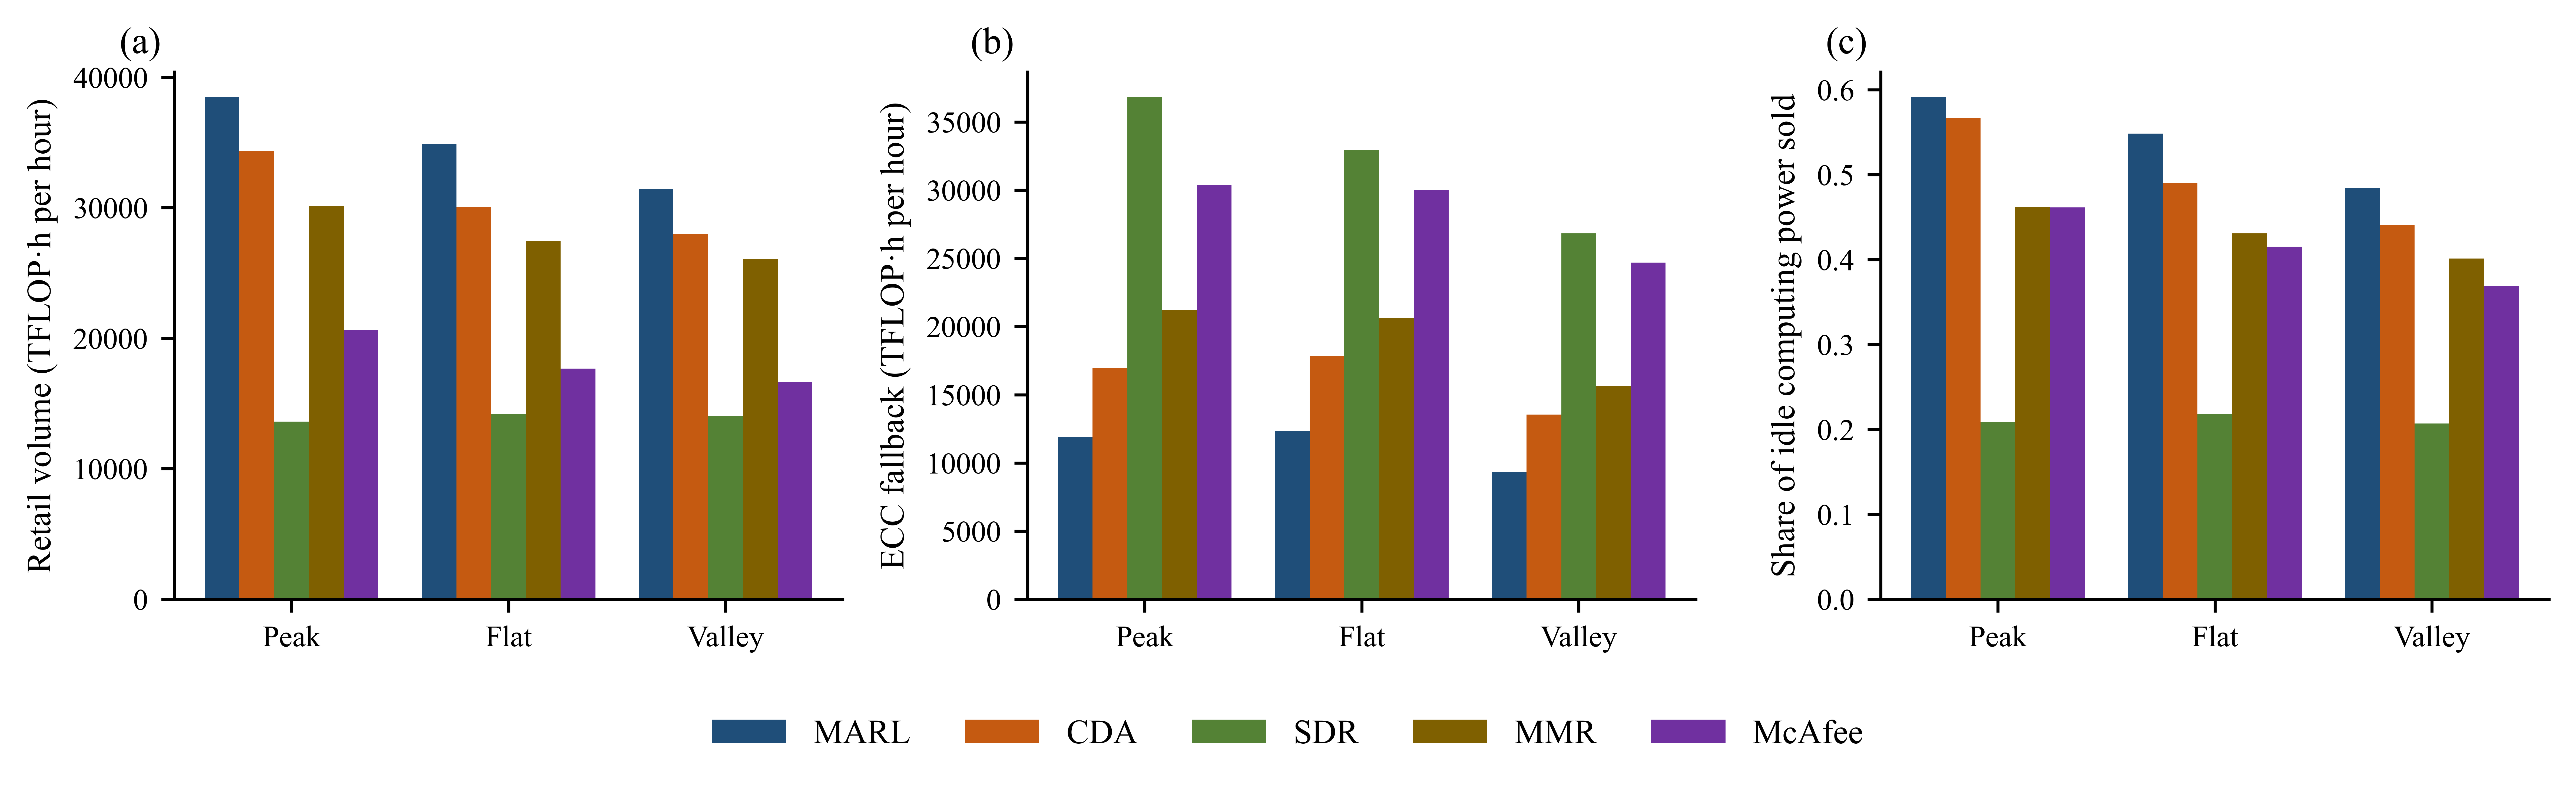

✅ 表格：C:\Users\Administrator\Desktop\多智能体强化学习定价\最终稿\cpm_v3\results\energy\tables
—— reproduction ——


,case,method,reference,unit_welfare,unit_welfare_reference,max_rel_diff,identical
0,main,marl,main\seed_0\eval_marl,159.050010,159.050010,0.0,True
1,flat,marl,sens_tariff_flat\seed_0\eval_marl,162.782693,162.782693,0.0,True
2,pv1.5,marl,energy_pv_1.5\seed_0\eval_marl,160.424122,160.424122,0.0,True
3,pv2,marl,energy_pv_2\seed_0\eval_marl,162.043638,162.043638,0.0,True
4,main,cda,main\seed_0\eval_cda,135.948230,135.948230,0.0,True
5,main,sdr,main\seed_0\eval_sdr,67.989462,67.989462,0.0,True
6,main,mmr,main\seed_0\eval_mmr,122.113008,122.113008,0.0,True
7,main,mcafee,main\seed_0\eval_mcafee,74.190949,74.190949,0.0,True


—— noise ——


,period,rel_diff_demand_buyers,rel_diff_demand_pros,rel_diff_demand,buyers_daily_corr,seed_sd_unit_welfare,seed_sd_welfare_per_day,seed_sd_p1_price_rel,seed_sd_internal_flow_share,seed_sd_idle_sold_share,seed_sd_buyer_savings_pc,seed_sd_prosumer_savings_pc,seed_sd_inter_profit_avg
0,peak,-0.028022,0.081544,0.053172,-0.192622,1.36481,164.583663,0.012654,0.006808,0.005095,0.358277,0.253201,177.331079
1,flat,0.013408,0.016914,0.016074,-0.192622,1.36481,164.583663,0.012654,0.006808,0.005095,0.358277,0.253201,177.331079
2,valley,-0.005365,-0.086811,-0.068590,-0.192622,1.36481,164.583663,0.012654,0.006808,0.005095,0.358277,0.253201,177.331079
3,all,-0.004715,-0.001836,-0.002525,-0.192622,1.36481,164.583663,0.012654,0.006808,0.005095,0.358277,0.253201,177.331079


—— scenarios ——


,case,label,period,unit_welfare,welfare_day,p1_rel,p2_rel,spread,p2_vol_day,ecc_vol_day,internal_share,idle_sold,com_share,elec_price_sold,elec_share_p1,buyer_savings_pc,prosumer_savings_pc,inter_profit_avg,d_unit_welfare,d_welfare_day,d_p1_rel,d_p2_rel,d_spread,d_p2_vol_day,d_ecc_vol_day,d_internal_share,d_idle_sold,d_com_share,d_elec_price_sold,d_elec_share_p1
0,main,"TOU, ξ = 0.1 (main)",all,159.050010,19179.986201,0.471005,0.740126,0.008755,827775.504100,266228.741100,0.756647,0.534812,0.452730,0.457810,0.204572,2.797032,5.181552,1927.132567,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,main,"TOU, ξ = 0.1 (main)",peak,155.184828,20357.538168,0.480389,0.743841,0.008634,923859.083200,285130.950000,0.764158,0.591721,0.436018,0.619035,0.269294,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,main,"TOU, ξ = 0.1 (main)",flat,154.995976,19398.514034,0.480845,0.746893,0.008680,837106.235467,295960.135200,0.738797,0.548582,0.456753,0.464653,0.203563,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,main,"TOU, ξ = 0.1 (main)",valley,166.808519,18176.423723,0.452739,0.729583,0.008936,754389.053333,223895.874400,0.771134,0.484343,0.461649,0.323285,0.150978,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,flat,"Flat, ξ = 0",all,162.782693,19580.538827,0.468118,0.764179,0.009813,841619.278100,248386.626500,0.772124,0.537478,0.453952,0.451132,0.203955,2.508374,4.967340,2297.196261,3.732683,400.552626,-0.002887,0.024053,0.001058,13843.774000,-17842.114600,0.015476,0.002666,0.001221,-0.006678,-0.000617
5,flat,"Flat, ξ = 0",peak,162.431486,22441.181134,0.475652,0.770043,0.009837,961390.208400,286427.860400,0.770457,0.633513,0.466986,0.452795,0.201285,NaN,NaN,NaN,7.246658,2083.642966,-0.004737,0.026202,0.001203,37531.125200,1296.910400,0.006299,0.041792,0.030968,-0.166239,-0.068009
6,flat,"Flat, ξ = 0",flat,160.244557,20377.760400,0.479046,0.771025,0.009660,875718.104000,279027.682933,0.758364,0.566131,0.457066,0.451568,0.199626,NaN,NaN,NaN,5.248581,979.246366,-0.001799,0.024131,0.000980,38611.868533,-16932.452267,0.019567,0.017549,0.000313,-0.013085,-0.003937
7,flat,"Flat, ξ = 0",valley,166.281638,16876.222383,0.448642,0.750775,0.009977,727673.165333,192384.747467,0.790899,0.451418,0.439031,0.449186,0.211867,NaN,NaN,NaN,-0.526880,-1300.201340,-0.004097,0.021192,0.001041,-26715.888000,-31511.126933,0.019765,-0.032925,-0.022618,0.125901,0.060889
8,pv1.5,"Peak–valley × 1.5, ξ = 0.15",all,160.424122,18641.647371,0.462683,0.746859,0.009368,808187.607600,234310.462000,0.775241,0.521332,0.453940,0.454415,0.211624,2.730242,4.745054,2073.272038,1.374112,-538.338830,-0.008322,0.006734,0.000613,-19587.896500,-31918.279100,0.018594,-0.013479,0.001209,-0.003395,0.007052
9,pv1.5,"Peak–valley × 1.5, ξ = 0.15",peak,152.067279,18212.134563,0.465633,0.747341,0.009383,849347.133600,244096.996000,0.776763,0.536299,0.405075,0.696387,0.320387,NaN,NaN,NaN,-3.117549,-2145.403605,-0.014756,0.003501,0.000748,-74511.949600,-41033.954000,0.012605,-0.055422,-0.030943,0.077352,0.051093


... (6 outputs left out)

—— pass_through ——


,comparison,mean_abs_dE,p1,p1_lo,p1_hi,floor,floor_lo,floor_hi,p2,p2_lo,p2_hi
0,"main vs flat tariff (same demand, main policy)",0.000742,0.3937,0.381272,0.404762,0.744131,0.741237,0.746815,0.243988,0.228813,0.259792


—— period ——


,method,period,p2_vol_h,ecc_vol_h,internal_share,idle_sold,p1_rel,p2_rel,spread,elec_price_sold,unit_welfare
0,MARL,peak,38494.128467,11880.456250,0.764158,0.591721,0.480389,0.743841,0.008634,0.619035,155.184828
1,MARL,flat,34879.426478,12331.672300,0.738797,0.548582,0.480845,0.746893,0.008680,0.464653,154.995976
2,MARL,valley,31432.877222,9328.994767,0.771134,0.484343,0.452739,0.729583,0.008936,0.323285,166.808519
3,MARL,all,34490.646004,11092.864213,0.756647,0.534812,0.471005,0.740126,0.008755,0.457810,159.050010
4,CDA,peak,34343.708183,16951.377700,0.669532,0.566831,0.558896,0.894219,0.011103,0.616050,132.683017
5,CDA,flat,30044.234167,17853.345500,0.627260,0.490624,0.535351,0.893798,0.011922,0.466734,130.384327
6,CDA,valley,27973.254200,13544.924656,0.673759,0.440474,0.554459,0.884678,0.010917,0.324804,144.959398
7,CDA,all,30342.485183,16012.195733,0.654572,0.490544,0.548683,0.890764,0.011343,0.460655,135.948230
8,SDR,peak,13617.767067,36842.239567,0.269872,0.208707,0.317862,0.864092,0.018198,0.583327,58.324934
9,SDR,flat,14214.958433,32963.984233,0.301299,0.218547,0.296093,0.838036,0.018050,0.458602,66.066756


In [6]:
R = EN.energy_report(SMOKE)
for k in ('reproduction', 'noise', 'scenarios', 'decomposition', 'amplitude', 'factors', 'pass_through', 'period'):
    print(f'—— {k} ——'); display(R.get(k))